# Forecasting Cambodia’s daily fuel prices
**At the end of today, what price should we predict for tomorrow?** One forecast per fuel, in Cambodian riel per litre (KHR/L). Compare Linear Regression, Random Tree and XGBoost with the price already known today.

Read the charts in order. The first part examines only the period before **24 September 2026** apart from auditing the calendar and source coverage. Four expanding validation windows then decide which inputs each algorithm uses. The last part opens the fixed test period and examines the cost of missing a price change.

Run all cells from the project with the Python dependencies in `requirements.txt`. The final fitting cell writes six study bundles under `models/study/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from gas_common import (DATA_PATH, FEATURES, MODELS_DIR, STUDY_FEATURES, TARGETS, TEST_START,
                        load_clean_data, make_features, metrics, save_model_bundle, train_test_split_time)
from random_tree_model import RandomTreeChangeRegressor
from train_xgboost import make_model as make_xgboost

%matplotlib inline
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "figure.dpi": 110, "font.size": 10})
names = {"regu_gas": "Regular gasoline", "diesel_gas": "Diesel"}
colors = {"regu_gas": "#b34b28", "diesel_gas": "#166e78"}

def date_ticks(ax):
    locator = mdates.AutoDateLocator(minticks=3, maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

## What does one row represent?
A date identifies one daily pair of prices. Ministry document numbers have leading zeroes, and the same document can span several dates. Preserve those identifiers for checking provenance. The forecasting inputs use dates and price history.

The audit compares the observed date index to a complete calendar. An absent row would be invisible in a column-by-column null count.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype={"moc_no": "string"})
raw["im_date"] = pd.to_datetime(raw["im_date"], format="%d-%m-%Y")
print(raw.agg(["count", "nunique"]).T.to_string())
print("Null cells by column:", raw.isna().sum().to_dict())
print("Repeated dates:", raw["im_date"].duplicated().sum())
assert raw["im_date"].notna().all() and raw["im_date"].is_unique
raw = raw.set_index("im_date").sort_index()
assert raw[TARGETS].gt(0).all().all(), "Inspect missing or non-positive price quotes"
daily = load_clean_data()
observed = daily.index.isin(raw.index)
gaps = daily.index[~observed]
print(f"{len(raw)} observed dates / {len(daily)} calendar dates, "
      f"{daily.index.min():%d %b %Y} to {daily.index.max():%d %b %Y}")
print("Dates absent from the file:", gaps.strftime("%Y-%m-%d").tolist())

            count  nunique
im_date       248      248
regu_gas      248       25
diesel_gas    248       28
moc_no        248       61
reference     248       39
Null cells by column: {'im_date': 0, 'regu_gas': 0, 'diesel_gas': 0, 'moc_no': 0, 'reference': 0}
Repeated dates: 0
248 observed dates / 249 calendar dates, 08 Mar 2026 to 11 Nov 2026
Dates absent from the file: ['2026-06-26']


## What price can we use on the missing day?
A posted price can remain in effect for several days. Carry the latest known quote forward for feature history and mark the filled date. Its actual price was unobserved, so it receives no weight as a training, validation or test outcome. The two panels around the gap use the same price axis.

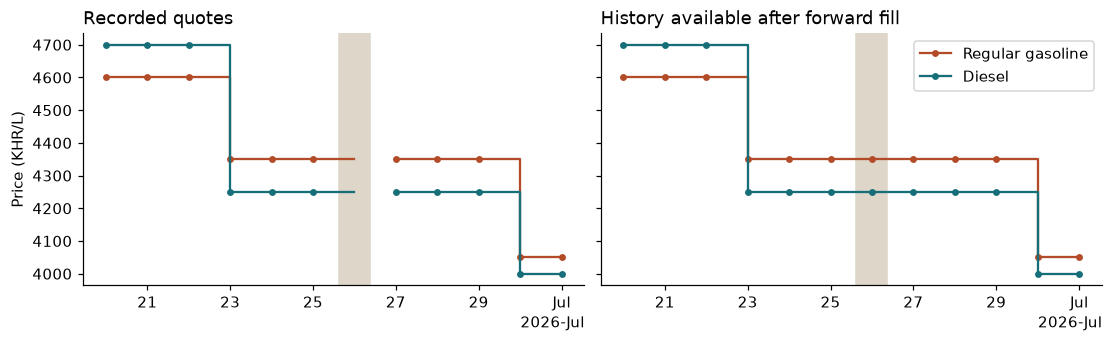

In [3]:
history = daily.loc[daily.index < TEST_START]
training_gaps = gaps[gaps < TEST_START]
if len(training_gaps):
    day = training_gaps[0]
    window = history.loc[day - pd.Timedelta(days=6):day + pd.Timedelta(days=5)]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True, layout="constrained")
    for ax, data, title in zip(axes, [raw[TARGETS].reindex(window.index), window],
                               ["Recorded quotes", "History available after forward fill"]):
        for fuel in TARGETS:
            ax.plot(data.index, data[fuel], "o-", drawstyle="steps-post", color=colors[fuel],
                    label=names[fuel], markersize=3.5)
        ax.axvspan(day - pd.Timedelta(hours=9), day + pd.Timedelta(hours=9), color="#ddd6c9", zorder=0)
        ax.set_title(title)
        date_ticks(ax)
    axes[0].set_ylabel("Price (KHR/L)")
    axes[1].legend()
    plt.show()

## How often do prices actually move?
Compare each fuel’s level with its first difference. The step chart preserves the duration of each price, while the stems expose abrupt revisions and quiet periods. For the change statistics, require quotes on both adjacent dates. The missing day and the day after it have uncertain daily changes.

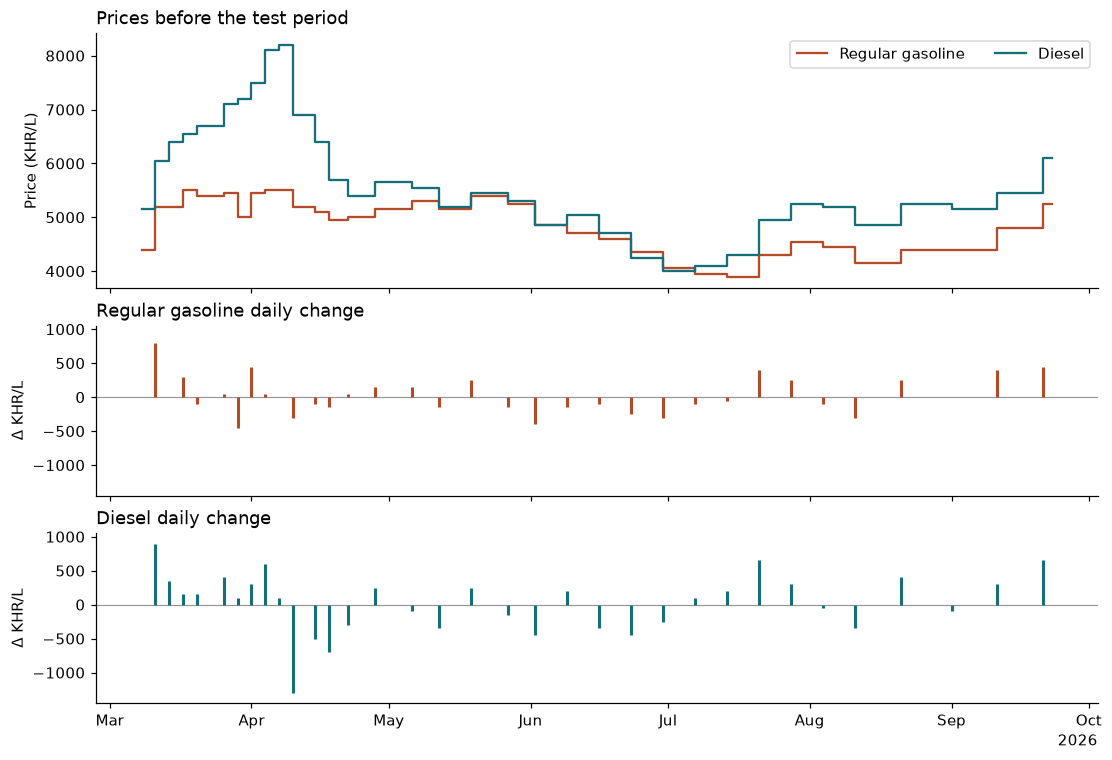

                  observed pairs  changes  flat (%)  largest rise  largest fall  change IQR
fuel                                                                                       
Regular gasoline             197       30      84.8         800.0        -450.0         0.0
Diesel                       197       33      83.2         900.0       -1300.0         0.0


In [4]:
observed_history = raw[TARGETS].reindex(history.index)
changes = observed_history.diff()
stats = []
fig, axes = plt.subplots(3, 1, figsize=(10, 6.8), sharex=True, layout="constrained",
                         gridspec_kw={"height_ratios": [1.5, 1, 1]})
for fuel, ax in zip(TARGETS, axes[1:]):
    price = history[fuel]
    axes[0].step(price.index, price, where="post", color=colors[fuel], label=names[fuel])
    delta = changes[fuel].dropna()
    moves = delta[delta.ne(0)]
    ax.axhline(0, color="#93999b", lw=0.8)
    ax.vlines(moves.index, 0, moves, color=colors[fuel], lw=2)
    ax.set(title=names[fuel] + " daily change", ylabel="Δ KHR/L")
    stats.append({"fuel": names[fuel], "observed pairs": len(delta), "changes": len(moves),
                  "flat (%)": 100 * delta.eq(0).mean(), "largest rise": delta.max(),
                  "largest fall": delta.min(), "change IQR": delta.quantile(.75) - delta.quantile(.25)})
axes[0].set(title="Prices before the test period", ylabel="Price (KHR/L)")
axes[0].legend(ncol=2)
for ax in axes[1:]:
    ax.set_ylim(-1450, 1050)
date_ticks(axes[-1])
plt.show()
print(pd.DataFrame(stats).set_index("fuel").round(1).to_string())

The middle half of daily changes spans zero KHR/L for both fuels. An IQR fence on all changes would flag **every** revision. Retain the recorded jumps in the response. They are exactly the events a forecaster must handle. For example, diesel’s largest fall is followed by several quotes at its new level.

In [5]:
drop_day = changes["diesel_gas"].idxmin()
print(raw.loc[drop_day - pd.Timedelta(days=1):drop_day + pd.Timedelta(days=3),
              ["diesel_gas", "reference"]].to_string())

            diesel_gas                             reference
im_date                                                     
2026-04-09        8200  Notification_No_1194__06.04.2026.pdf
2026-04-10        6900  Notification_No_1255__09.04.2026.pdf
2026-04-11        6900  Notification_No_1255__09.04.2026.pdf
2026-04-12        6900  Notification_No_1255__09.04.2026.pdf
2026-04-13        6900  Notification_No_1255__09.04.2026.pdf


## Does a weekly rhythm persist?
A correlation between successive **levels** can arise simply because most prices carry over. Compare it with correlations of daily **changes**. Then inspect both fuels’ revision dates on a calendar. A mark indicates that at least one observed price changed on that date.

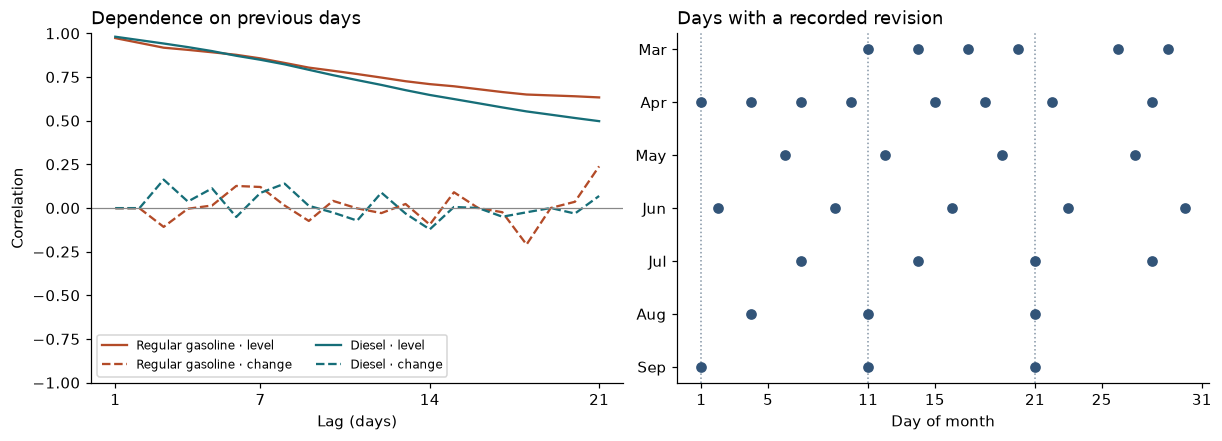

In [6]:
fig, (ax, cal) = plt.subplots(1, 2, figsize=(11, 3.9), layout="constrained")
lags = range(1, 22)
for fuel in TARGETS:
    for values, style, label in [(observed_history[fuel], "-", "level"), (changes[fuel], "--", "change")]:
        ax.plot(lags, [values.autocorr(k) for k in lags], style, color=colors[fuel],
                label=f"{names[fuel]} · {label}")
ax.axhline(0, color="#888", lw=.8)
ax.set(xlabel="Lag (days)", ylabel="Correlation", ylim=(-1, 1), xticks=[1, 7, 14, 21],
       title="Dependence on previous days")
ax.legend(fontsize=8, ncol=2)
valid = changes.dropna()
move_dates = valid.index[valid.ne(0).any(axis=1)]
months = history.index.to_period("M").unique()
for i, month in enumerate(months):
    dates = move_dates[move_dates.to_period("M") == month]
    cal.scatter(dates.day, np.full(len(dates), i), color="#325478")
for boundary in [1, 11, 21]:
    cal.axvline(boundary, lw=1, ls=":", color="#8495a5", zorder=0)
cal.set(yticks=range(len(months)), yticklabels=[m.strftime("%b") for m in months],
        xticks=[1, 5, 11, 15, 21, 25, 31], xlabel="Day of month",
        title="Days with a recorded revision")
cal.invert_yaxis()
plt.show()

The spring revisions come close together. Several summer revisions are seven days apart, and the late-training revisions cluster on the 1st, 11th and 21st. That changing cadence makes both weekly phase and ten-day boundaries candidates to test. The record covers less than one year, so it gives us no repeated annual cycle to estimate.

## From price history to a forecast row
For a forecast dated *t*, `lag_1` is yesterday’s quote, `lag_7` is the quote a week ago, `roll_mean_7` averages *t−7* through *t−1*, and `other_lag_1` is the other fuel’s quote yesterday. The study adds two groups of inputs.

| Group | Available at forecast time | Question |
|---|---|---|
| Recent revisions | Yesterday’s change and the number of consecutive unchanged days through yesterday. The first observed quote starts the initial run. | Does the size or age of the last revision help? |
| Calendar timing | Sine and cosine of the forecast weekday and a flag for the 1st, 11th or 21st. | Does the timing of revisions repeat? |

The following example crosses a price revision. The change in price first reaches the feature columns **the following day**. The prefix check independently rebuilds the features through one forecast date while hiding both fuels’ prices on that date.

In [7]:
frames = {fuel: make_features(daily, fuel, include_study=True) for fuel in TARGETS}
timing = ["weekday_sin", "weekday_cos", "ten_day_boundary"]
recent = ["last_change", "flat_days"]
price_lags = ["lag_1", "lag_7", "other_lag_1", "roll_mean_7"]
feature_sets = {
    "Yesterday only": ["lag_1"],
    "Price history": price_lags,
    "History + revisions": price_lags + recent,
    "History + timing": price_lags + timing,
    "History + both": price_lags + recent + timing,
    "Team seven": FEATURES,
}
example = history.index[-3]
prefix = daily.loc[:example].copy()
prefix.loc[example, TARGETS] = np.nan
for fuel in TARGETS:
    cols = FEATURES + STUDY_FEATURES
    pd.testing.assert_series_equal(make_features(prefix, fuel, include_study=True).loc[example, cols],
                                   frames[fuel].loc[example, cols])
print(frames["regu_gas"].loc[example - pd.Timedelta(days=1):example + pd.Timedelta(days=2),
      ["lag_1", "lag_7", "roll_mean_7", "last_change", "flat_days", "ten_day_boundary", "y"]]
      .round(1).to_string())

             lag_1   lag_7  roll_mean_7  last_change  flat_days  ten_day_boundary       y
date                                                                                     
2026-09-20  4800.0  4800.0       4800.0          0.0        8.0                 0  4800.0
2026-09-21  4800.0  4800.0       4800.0          0.0        9.0                 1  5250.0
2026-09-22  5250.0  4800.0       4864.3        450.0        0.0                 0  5250.0
2026-09-23  5250.0  4800.0       4928.6          0.0        1.0                 0  5250.0


## Which inputs earn their place on later dates?
Reserve the project’s final test dates. Within the earlier period, validate on four consecutive 28-day windows, expanding the training history each time. All candidates forecast the same observed outcomes. Seven initial dates supply lag history. The gap day supplies history only.

The three algorithms use the same six candidate feature sets. Linear Regression fits a standard scaler inside each training fold. Random Tree uses the project’s randomized split tree with conservative depth, leaf size and change weight. XGBoost uses the project’s depth-two boosted change model. Both trees predict an adjustment to yesterday’s price. Keep these settings fixed to isolate the effect of the features. Choose each algorithm’s feature set by the lowest pooled validation RMSE, breaking ties by fewer inputs. Persistence predicts yesterday’s price and joins the comparison without fitting.

In [8]:
splits = {fuel: train_test_split_time(frame) for fuel, frame in frames.items()}
train_calendar = splits[TARGETS[0]][0].index
folds = []
for fit_idx, val_idx in TimeSeriesSplit(n_splits=4, test_size=28).split(train_calendar):
    fit_dates, val_dates = train_calendar[fit_idx], train_calendar[val_idx]
    fit_dates = fit_dates[fit_dates.isin(raw.index)]
    val_dates = val_dates[val_dates.isin(raw.index)]
    assert fit_dates.max() < val_dates.min() <= val_dates.max() < TEST_START
    folds.append((fit_dates, val_dates))
print(pd.DataFrame([(a.min().date(), a.max().date(), len(a), b.min().date(), b.max().date(), len(b))
                    for a, b in folds], columns=["fit from", "fit to", "n fit", "validate from",
                                                  "validate to", "n validate"],
                   index=range(1, len(folds)+1)).rename_axis("fold").to_string())

        fit from      fit to  n fit validate from validate to  n validate
fold                                                                     
1     2026-03-15  2026-06-03     81    2026-06-04  2026-07-01          27
2     2026-03-15  2026-07-01    108    2026-07-02  2026-07-29          28
3     2026-03-15  2026-07-29    136    2026-07-30  2026-08-26          28
4     2026-03-15  2026-08-26    164    2026-08-27  2026-09-23          28


In [9]:
def new_model(name):
    if name == "Linear Regression":
        return make_pipeline(StandardScaler(), LinearRegression())
    if name == "Random Tree":
        return RandomTreeChangeRegressor(feature_mode="levels", max_depth=2, min_samples_leaf=20,
                                         change_weight=0.5, leaf_smoothing=50)
    if name == "XGBoost":
        return make_xgboost().set_params(estimator__n_jobs=1)
    raise ValueError(name)

algorithms = ["Linear Regression", "Random Tree", "XGBoost"]
def validate(train, algorithm, columns):
    squared_errors = []
    for fit_dates, val_dates in folds:
        fit, val = train.loc[fit_dates], train.loc[val_dates]
        if algorithm == "Persistence":
            prediction = val["lag_1"]
        else:
            model = new_model(algorithm).fit(fit[columns], fit["y"])
            prediction = model.predict(val[columns])
        squared_errors.extend((val["y"] - prediction) ** 2)
    return np.sqrt(np.mean(squared_errors))

records = []
for fuel, (train, _) in splits.items():
    for algorithm in algorithms + ["Persistence"]:
        candidates = feature_sets if algorithm in algorithms else {"Yesterday only": ["lag_1"]}
        for label, columns in candidates.items():
            records.append({"fuel": fuel, "model": algorithm, "inputs": label, "count": len(columns),
                            "CV RMSE": validate(train, algorithm, columns)})
cv = pd.DataFrame(records).sort_values(["CV RMSE", "count"], kind="stable")
selected = cv.drop_duplicates(["fuel", "model"]).set_index(["fuel", "model"])
cv_choice = {fuel: selected.loc[fuel]["CV RMSE"].idxmin() for fuel in TARGETS}
print(selected.sort_index().round(2).to_string())

                                      inputs  count  CV RMSE
fuel       model                                            
diesel_gas Linear Regression  Yesterday only      1   129.20
           Persistence        Yesterday only      1   127.25
           Random Tree         Price history      4   128.09
           XGBoost            Yesterday only      1   131.75
regu_gas   Linear Regression  Yesterday only      1   113.14
           Persistence        Yesterday only      1    92.27
           Random Tree        Yesterday only      1    92.73
           XGBoost             Price history      4    97.75


## How much does feature selection matter?
Each square shows validation RMSE in KHR/L. Read across a row to compare inputs for one algorithm. The caption above each panel gives the persistence error on the same days.

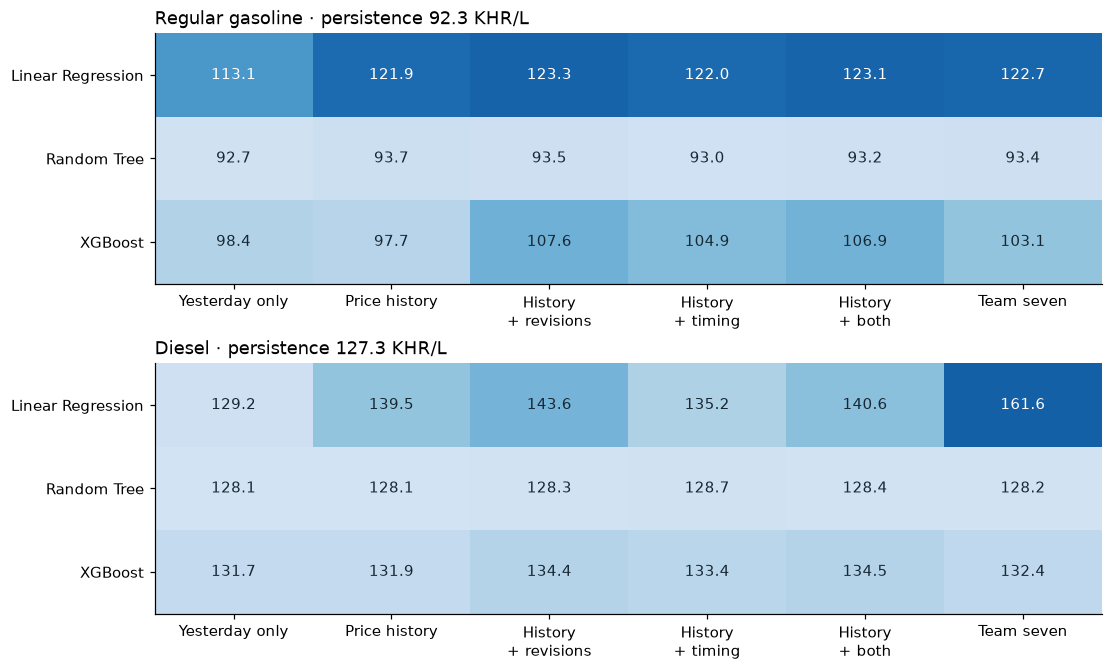

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
for ax, fuel in zip(axes, TARGETS):
    grid = (cv[cv.fuel.eq(fuel)].pivot(index="model", columns="inputs", values="CV RMSE")
            .loc[algorithms, list(feature_sets)])
    im = ax.imshow(grid, cmap="Blues", vmin=grid.min().min()-10, vmax=grid.max().max()+10, aspect="auto")
    for i, row in enumerate(grid.to_numpy()):
        for j, value in enumerate(row):
            ax.text(j, i, f"{value:.1f}", ha="center", va="center",
                    color="white" if im.norm(value) > .60 else "#172833")
    ax.set(yticks=range(len(grid)), yticklabels=grid.index, xticks=range(len(grid.columns)),
           xticklabels=[s.replace(" + ", "\n+ ") for s in grid.columns])
    baseline = selected.loc[(fuel, "Persistence"), "CV RMSE"]
    ax.set_title(f"{names[fuel]} · persistence {baseline:.1f} KHR/L")
plt.show()

## Fit the six study models
Refit each selected configuration on every eligible pre-test observation for its fuel. Persist the model, ordered input names and training period using the repository’s bundle format. Each test-day prediction can then use the actual price available through the day before. This evaluates successive one-day forecasts across the holdout.

In [11]:
fitted = {}
for fuel, (train, _) in splits.items():
    fit = train.loc[train.index.isin(raw.index)]
    for algorithm in algorithms:
        label = selected.loc[(fuel, algorithm), "inputs"]
        cols = feature_sets[label]
        model = new_model(algorithm).fit(fit[cols], fit["y"])
        fitted[fuel, algorithm] = (model, cols)
        path = save_model_bundle(model, model_name=algorithm, author="study", target=fuel,
                                 features=cols, train=fit, out_dir=MODELS_DIR / "study")
        print(f"{path.relative_to(ROOT)} · {len(fit)} observed labels · {label}")

models/study/regu_gas__linear_regression__study.pkl · 192 observed labels · Yesterday only
models/study/regu_gas__random_tree__study.pkl · 192 observed labels · Yesterday only
models/study/regu_gas__xgboost__study.pkl · 192 observed labels · Price history
models/study/diesel_gas__linear_regression__study.pkl · 192 observed labels · Yesterday only
models/study/diesel_gas__random_tree__study.pkl · 192 observed labels · Price history
models/study/diesel_gas__xgboost__study.pkl · 192 observed labels · Yesterday only


## How accurate were the one-day forecasts?
RMSE gives larger misses more weight. MAE describes the mean absolute miss in KHR/L. A positive RMSE gain means the model reduced error against persistence. The validation choice was made before opening these dates.

In [12]:
predictions, scores, slices = {}, [], []
for fuel, (_, test) in splits.items():
    test = test.loc[test.index.isin(raw.index)]
    pred = pd.DataFrame({"Actual": test["y"], "Persistence": test["lag_1"]})
    for algorithm in algorithms:
        model, cols = fitted[fuel, algorithm]
        pred[algorithm] = model.predict(test[cols])
    predictions[fuel] = pred
    moved = pred["Actual"].ne(pred["Persistence"])
    base_rmse = metrics(pred["Actual"], pred["Persistence"])["RMSE"]
    for algorithm in ["Persistence"] + algorithms:
        score = metrics(pred["Actual"], pred[algorithm])
        scores.append({"fuel": fuel, "model": algorithm, **score,
                       "RMSE gain": base_rmse - score["RMSE"], "CV choice": algorithm == cv_choice[fuel]})
        error = (pred[algorithm] - pred["Actual"]).abs()
        for label, mask in [("Changed", moved), ("Flat", ~moved)]:
            slices.append({"fuel": fuel, "model": algorithm, "days": label, "n": int(mask.sum()),
                           "MAE": error[mask].mean()})
    print(f"{names[fuel]} · {len(pred)} dates · {pred.index.min():%d %b}–{pred.index.max():%d %b %Y}")
board = pd.DataFrame(scores).sort_values(["fuel", "RMSE"])
print(board.set_index(["fuel", "model"]).round(2).to_string())

Regular gasoline · 49 dates · 24 Sep–11 Nov 2026
Diesel · 49 dates · 24 Sep–11 Nov 2026
                                MAE   RMSE    R2  MAPE%  RMSE gain  CV choice
fuel       model                                                             
diesel_gas Linear Regression  18.87  65.80  0.87   0.33       1.59      False
           Persistence        13.27  67.39  0.86   0.24       0.00       True
           Random Tree        14.25  67.53  0.86   0.25      -0.15      False
           XGBoost            34.82  68.27  0.86   0.62      -0.88      False
regu_gas   XGBoost            29.08  52.52  0.80   0.56       0.93      False
           Linear Regression  19.30  52.97  0.80   0.37       0.49      False
           Random Tree        13.63  53.45  0.80   0.26       0.01      False
           Persistence        12.24  53.45  0.80   0.24       0.00       True


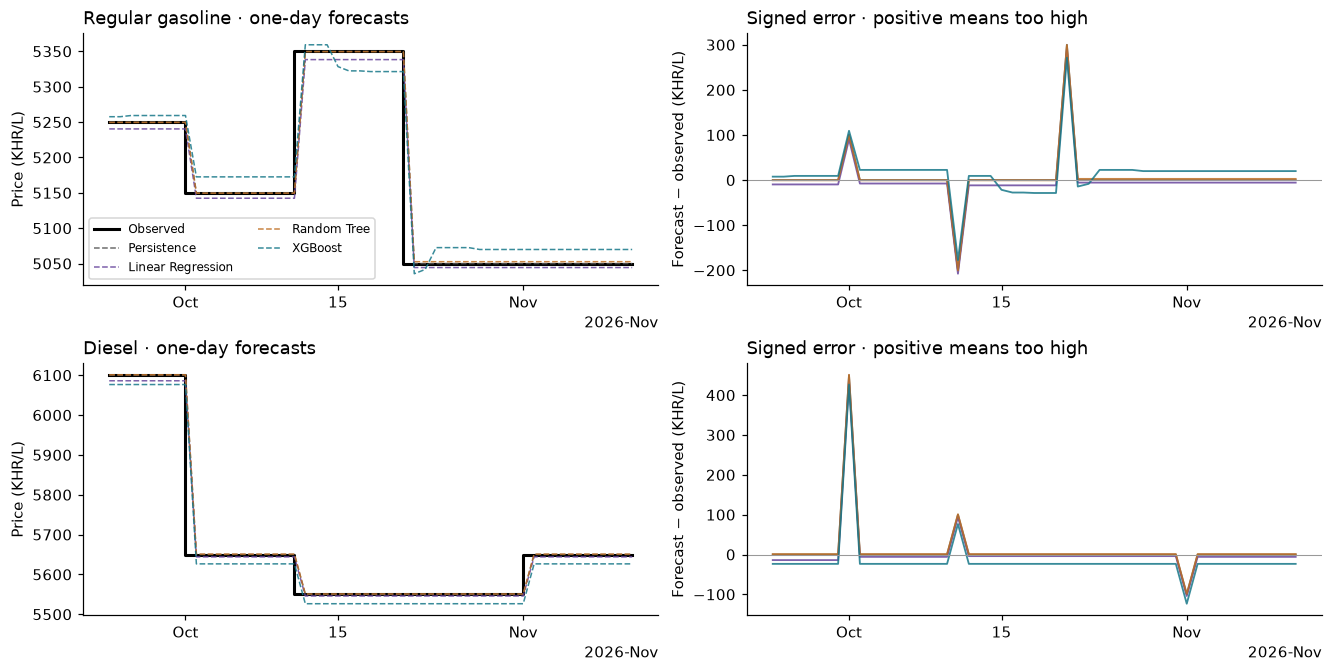

In [13]:
palette = {"Persistence": "#555555", "Linear Regression": "#67459c",
           "Random Tree": "#bf7025", "XGBoost": "#167788"}
fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")
for (level, residual), fuel in zip(axes, TARGETS):
    pred = predictions[fuel]
    level.step(pred.index, pred["Actual"], where="post", color="black", lw=2, label="Observed")
    for name, color in palette.items():
        level.plot(pred.index, pred[name], color=color, alpha=.85, ls="--", lw=1, label=name)
        residual.plot(pred.index, pred[name] - pred["Actual"], color=color, lw=1.2, alpha=.85)
    residual.axhline(0, color="#999999", lw=.7)
    level.set(title=names[fuel] + " · one-day forecasts", ylabel="Price (KHR/L)")
    residual.set(title="Signed error · positive means too high", ylabel="Forecast − observed (KHR/L)")
    date_ticks(level)
    date_ticks(residual)
axes[0, 0].legend(fontsize=8, ncol=2)
plt.show()

## Where does the error come from?
After forecasting, group the errors by whether the observed price changed from yesterday’s available price. Keep the count beside each average. With very few changes, one missed revision can switch the RMSE ranking.

In [14]:
segments = pd.DataFrame(slices).set_index(["fuel", "model", "days"])
print(segments[["n", "MAE"]].unstack("days").round(2).to_string())
for fuel in TARGETS:
    results = board[board.fuel.eq(fuel)]
    winner = results.iloc[0]
    choice = results.loc[results["CV choice"]].iloc[0]
    print(f"\n{names[fuel]}: validation selected {choice['model']}; its test RMSE was "
          f"{choice['RMSE']:.2f} KHR/L. Lowest observed test RMSE: {winner['model']} "
          f"({winner['RMSE']:.2f} KHR/L).")

                                   n          MAE       
days                         Changed Flat Changed   Flat
fuel       model                                        
diesel_gas Linear Regression       3   46  211.39   6.31
           Persistence             3   46  216.67   0.00
           Random Tree             3   46  217.01   1.02
           XGBoost                 3   46  208.84  23.47
regu_gas   Linear Regression       3   46  195.43   7.82
           Persistence             3   46  200.00   0.00
           Random Tree             3   46  199.84   1.48
           XGBoost                 3   46  186.03  18.84

Regular gasoline: validation selected Persistence; its test RMSE was 53.45 KHR/L. Lowest observed test RMSE: XGBoost (52.52 KHR/L).

Diesel: validation selected Persistence; its test RMSE was 67.39 KHR/L. Lowest observed test RMSE: Linear Regression (65.80 KHR/L).


## What would we use for the next forecast?

**Carry the latest posted price forward for both fuels.** This rule had the lowest pooled validation RMSE for each fuel. Among the fitted models, validation favored Random Tree for both fuels. None of the six selected fits retained the revision-age or calendar features. The calendar identified when some revisions were likely, but predicting the signed size of a revision is a harder task.

On the final 49 days, regular-gasoline XGBoost reduced RMSE by **0.93 KHR/L** against persistence. Its mean absolute error on the three revision days fell from **200.00** to **186.03 KHR/L**, while its average miss on the 46 flat days was **18.84 KHR/L**. Diesel Linear Regression reduced RMSE by **1.59 KHR/L**, with a **6.31 KHR/L** average miss on flat days. Persistence was exact on every flat day and had the lowest overall MAE for both fuels. Three price moves per fuel give little evidence that either RMSE lead will repeat.

## Course reading behind the choices
The week numbers refer to the PDFs in the sibling course directory. Week 7 had no PDF there.

| Lectures | Application in this study |
|---|---|
| [1 · First contact](../data-modeling/Week1_Introduction_to_Data_Modeling_and_Preprocessing.pdf), [2 · Missing values](../data-modeling/Week2_Data_Quality_Missing_Values.pdf), [9 · Integration](../data-modeling/Week9_Data_Integration.pdf) | Identify the daily grain, verify its key and distinguish missing dates from empty cells. |
| [3 · Outliers](../data-modeling/Week3_Data_Quality_Outliers.pdf), [12 · Visualization](../data-modeling/Week12_Visualization.pdf) | Inspect the distribution of changes, check extreme observations against their source rows and compare the gap before and after filling on shared axes. |
| [4 · Scaling](../data-modeling/Week4_Normalization_and_Standardization.pdf), [5 · Encoding](../data-modeling/Week5_Categorical_Encoding_Slide.pdf), [6 · Feature engineering](../data-modeling/Week6_Feature_Engineering.pdf) | Standardize inside each linear fit, encode weekly phase cyclically, and derive lagged revision and timing features. |
| [8 · Feature selection and PCA](../data-modeling/Week8_Feature_Selection_and_PCA.pdf) | Evaluate small, interpretable input groups on subsequent dates. Each retained feature group has a measured validation error. |
| [10 · Imbalanced data](../data-modeling/Week10_Imbalanced_Data.pdf) | Apply the rare-outcome lesson to regression by measuring errors separately on changed and flat days. Preserve the observed frequency and order of dates. |
| [11 · Time series](../data-modeling/Week11_Time_Series.pdf), pp. 41–51 and 52–67 | Mark filled history, shift before rolling, use expanding windows and compare every forecast to yesterday’s price. |

## Dashboard results
The Data analysis tab uses the following machine-readable summary of this run. Refresh its figures and results together with `python src/import_notebook_figures.py fuel_price_study.ipynb`.

In [15]:
from IPython.display import display

study = {"folds": len(folds), "featureSets": len(feature_sets), "fuels": {}}
errors_by_segment = segments.sort_index()
for fuel, pred in predictions.items():
    models = []
    for row in board[board.fuel.eq(fuel)].to_dict("records"):
        name = row["model"]
        choice = selected.loc[(fuel, name)]
        errors = errors_by_segment.loc[(fuel, name)]
        models.append({
            "name": name, "inputs": choice["inputs"], "validationRMSE": choice["CV RMSE"],
            "rmse": row["RMSE"], "mae": row["MAE"], "flatMAE": errors.loc["Flat", "MAE"] if errors.loc["Flat", "n"] else None,
            "changeMAE": errors.loc["Changed", "MAE"] if errors.loc["Changed", "n"] else None,
        })
    study["fuels"][fuel] = {
        "choice": cv_choice[fuel],
        "trainDays": int(splits[fuel][0].index.isin(raw.index).sum()),
        "testDates": pred.index.strftime("%Y-%m-%d").tolist(),
        "changed": pred["Actual"].ne(pred["Persistence"]).tolist(),
        "models": models,
    }
display({"application/json": study}, raw=True)